# Bài thực hành 4 – TV6: Đánh giá và thử nghiệm nâng cao
So sánh sự tương đồng của ảnh bằng **Wavelet Hash + khoảng cách Hamming**.

**Quy ước chung của nhóm**
- `label`: 1 = cặp tương tự, 0 = không tương tự
- `distance`: khoảng cách Hamming (số bit khác nhau) – *càng nhỏ càng giống*
- Dự đoán tương tự khi `distance <= threshold`
- ROC dùng điểm số **`-distance`** (điểm cao = giống) – đã xử lý trong `evaluation.roc_auc_from_distances()`
- Mọi cấu hình đều tạo hash **64 bit (8×8)** để so sánh công bằng

In [1]:
import os, sys
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt

# tự tìm evaluation.py / experiments.py ở thư mục hiện tại hoặc src/
for p in (".", "src", "../src"):
    if os.path.exists(os.path.join(p, "evaluation.py")):
        sys.path.insert(0, os.path.abspath(p)); break

import evaluation as ev
import experiments as ex

pd.set_option("display.width", 160)
os.makedirs("output", exist_ok=True)

## 1. Dữ liệu
Thư mục ảnh gốc: đặt `DATA_DIR` nếu notebook không tự tìm thấy (ví dụ `r"..\data\input"`).
Nếu không có ảnh, notebook dùng **ảnh giả lập** để chạy thử – khi đó kết quả chỉ mang tính minh hoạ.

Từ mỗi ảnh gốc, tạo:
- **Cặp tương tự (1):** ảnh gốc vs bản đã biến đổi (đổi sáng, nhiễu, mờ, nén JPEG, xoay 5°, cắt 90%)
- **Cặp khác nhau (0):** ảnh gốc vs ảnh (gốc hoặc đã biến đổi) của một ảnh khác

In [2]:
DATA_DIR = None   # ví dụ: r"..\data\input"

if DATA_DIR is None:
    for cand in ("../data/input", "data/input", "../../data/input"):
        if os.path.isdir(cand):
            DATA_DIR = cand; break

base = ex.load_images(DATA_DIR) if DATA_DIR else {}
USING_DEMO = len(base) < 2
if USING_DEMO:
    print("⚠ Không tìm thấy >= 2 ảnh -> dùng ảnh GIẢ LẬP (chỉ để minh hoạ).")
    base = ex.make_demo_images(n=20)
elif len(base) < 20:
    print(f"⚠ Chỉ có {len(base)} ảnh gốc: ROC/AUC sẽ kém ổn định, nên dùng >= 20 ảnh.")
print("Số ảnh gốc:", len(base), "| thư mục:", DATA_DIR)

images, pairs = ex.build_dataset(base, neg_per_pos=1.0, seed=0)
print(pairs.label.value_counts().rename({1: "tương tự", 0: "khác nhau"}).to_string())
pairs.head()

⚠ Chỉ có 15 ảnh gốc: ROC/AUC sẽ kém ổn định, nên dùng >= 20 ảnh.
Số ảnh gốc: 15 | thư mục: ../data/input
label
tương tự     105
khác nhau    105


,img1,img2,label,variant
0,anh_dem,anh_dem::darken,1,darken
1,anh_dem,anh_dem::brighten,1,brighten
2,anh_dem,anh_dem::gauss_noise,1,gauss_noise
3,anh_dem,anh_dem::blur,1,blur
4,anh_dem,anh_dem::jpeg_q30,1,jpeg_q30


## 2. Hash và khoảng cách với cấu hình mặc định (haar, 1 mức, median)

In [3]:
DEFAULT = dict(wavelet="haar", level=1, quant="median")

name = next(iter(base))
for t in ("darken", "jpeg_q30"):
    h0 = ex.wavelet_hash(images[name], **DEFAULT)
    h1 = ex.wavelet_hash(images[f"{name}::{t}"], **DEFAULT)
    print(f"{name} vs {t:9s}: {ex.bits_to_hex(h0)} | {ex.bits_to_hex(h1)} | Hamming = {ex.hamming(h0, h1)}")
other = list(base)[1]
print(f"{name} vs {other}: Hamming = {ex.hamming(ex.wavelet_hash(images[name], **DEFAULT), ex.wavelet_hash(images[other], **DEFAULT))}")

anh_dem vs darken   : 10187e7e7e7e1c0c | 10187e7e7e7e1c0c | Hamming = 0
anh_dem vs jpeg_q30 : 10187e7e7e7e1c0c | 10187e7e7e7e1c0c | Hamming = 0
anh_dem vs buom: Hamming = 20


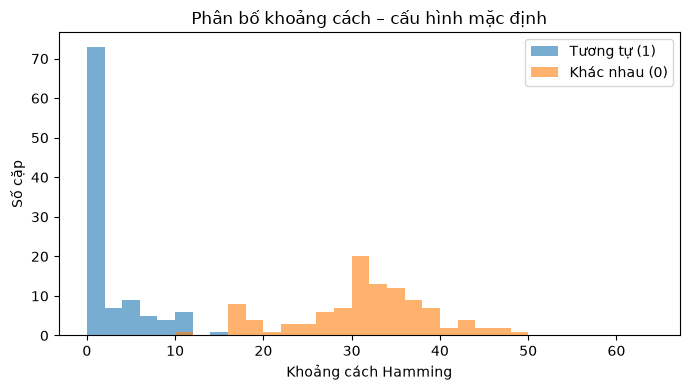

In [4]:
res = ex.run_config(pairs, images, **DEFAULT)
df = res["df"]

plt.figure(figsize=(7, 4))
bins = np.arange(0, 66, 2)
plt.hist(df.loc[df.label == 1, "distance"], bins=bins, alpha=.6, label="Tương tự (1)")
plt.hist(df.loc[df.label == 0, "distance"], bins=bins, alpha=.6, label="Khác nhau (0)")
plt.xlabel("Khoảng cách Hamming"); plt.ylabel("Số cặp"); plt.legend()
plt.title("Phân bố khoảng cách – cấu hình mặc định"); plt.tight_layout(); plt.show()

## 3. Chỉ số đánh giá theo ngưỡng
Accuracy, Recall (độ nhạy), Specificity (độ đặc hiệu), Precision tính từ nhãn thật và nhãn dự đoán (`evaluation.py`).
Ngưỡng tham khảo được chọn theo **Youden J = Recall + Specificity − 1**.

In [5]:
y = df.label.astype(int).tolist()
d = df.distance.astype(int).tolist()

best_t = res["threshold"]
thresholds = sorted(set(range(0, 33, 2)) | {best_t})
metrics_table = pd.DataFrame(ev.evaluate_thresholds(y, d, thresholds))
print("Ngưỡng được chọn (Youden J):", best_t)
metrics_table.round(3)

Ngưỡng được chọn (Youden J): 14


,threshold,comparison,TP,FP,TN,FN,accuracy,recall,specificity,precision
0,0,<=,68,0,105,37,0.824,0.648,1.000,1.000
1,2,<=,80,0,105,25,0.881,0.762,1.000,1.000
2,4,<=,87,0,105,18,0.914,0.829,1.000,1.000
3,6,<=,94,0,105,11,0.948,0.895,1.000,1.000
4,8,<=,98,0,105,7,0.967,0.933,1.000,1.000
5,10,<=,103,1,104,2,0.986,0.981,0.990,0.990
6,12,<=,104,1,104,1,0.990,0.990,0.990,0.990
7,14,<=,105,1,104,0,0.995,1.000,0.990,0.991
8,16,<=,105,9,96,0,0.957,1.000,0.914,0.921
9,18,<=,105,13,92,0,0.938,1.000,0.876,0.890


In [6]:
m = res["metrics"]
print(f"Tại ngưỡng {best_t}:  TP={m['TP']}  FP={m['FP']}  TN={m['TN']}  FN={m['FN']}")
print(f"Accuracy={m['accuracy']:.3f}  Recall={m['recall']:.3f}  "
      f"Specificity={m['specificity']:.3f}  Precision={m['precision']:.3f}")
metrics_table.to_csv("output/metrics_table.csv", index=False)

Tại ngưỡng 14:  TP=105  FP=1  TN=104  FN=0
Accuracy=0.995  Recall=1.000  Specificity=0.990  Precision=0.991


## 4. Đường cong ROC và AUC
Mỗi ngưỡng khoảng cách cho một điểm (FPR, TPR). Vì khoảng cách càng nhỏ càng giống nên điểm số = `-distance`.

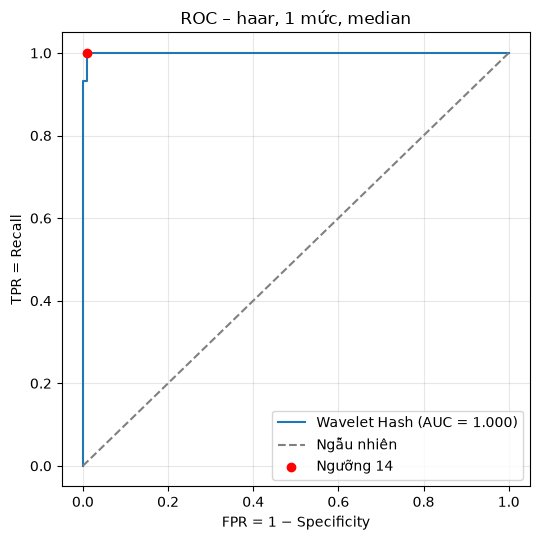

AUC = 0.9996


In [7]:
roc = res["roc"]
fpr_pt = m["FP"] / (m["FP"] + m["TN"]); tpr_pt = m["recall"]

plt.figure(figsize=(5.5, 5.5))
plt.plot(roc["fpr"], roc["tpr"], drawstyle="steps-post", label=f"Wavelet Hash (AUC = {roc['auc']:.3f})")
plt.plot([0, 1], [0, 1], "--", color="gray", label="Ngẫu nhiên")
plt.scatter([fpr_pt], [tpr_pt], c="red", zorder=3, label=f"Ngưỡng {best_t}")
plt.xlabel("FPR = 1 − Specificity"); plt.ylabel("TPR = Recall")
plt.title("ROC – haar, 1 mức, median"); plt.legend(loc="lower right"); plt.grid(alpha=.3)
plt.tight_layout(); plt.savefig("output/roc_default.png", dpi=150); plt.show()
print("AUC =", round(roc["auc"], 4))

## 5. So sánh wavelet, mức phân rã và cách lượng tử hoá
Lưới cấu hình: wavelet {haar, db2, sym2, coif1} × mức phân rã {1, 2, 3} × lượng tử hoá {median, mean}.
Ảnh được resize về `8·2^level` để sau `level` lần phân rã, hệ số xấp xỉ LL luôn là 8×8 = 64 bit.

In [8]:
summary, results = ex.compare_configs(pairs, images)
summary.to_csv("output/experiments_summary.csv", index=False)
summary.round(3)

,config,wavelet,level,quant,auc,threshold,accuracy,recall,specificity,precision
0,db2|L1|mean,db2,1,mean,1.000,12,1.000,1.000,1.000,1.000
1,sym2|L1|mean,sym2,1,mean,1.000,12,1.000,1.000,1.000,1.000
2,coif1|L1|median,coif1,1,median,1.000,10,1.000,1.000,1.000,1.000
3,coif1|L1|mean,coif1,1,mean,1.000,11,1.000,1.000,1.000,1.000
4,coif1|L2|mean,coif1,2,mean,1.000,12,1.000,1.000,1.000,1.000
5,coif1|L3|median,coif1,3,median,1.000,12,1.000,1.000,1.000,1.000
6,coif1|L3|mean,coif1,3,mean,1.000,12,1.000,1.000,1.000,1.000
7,coif1|L2|median,coif1,2,median,1.000,14,0.995,1.000,0.990,0.991
8,db2|L1|median,db2,1,median,1.000,12,0.995,1.000,0.990,0.991
9,sym2|L1|median,sym2,1,median,1.000,12,0.995,1.000,0.990,0.991


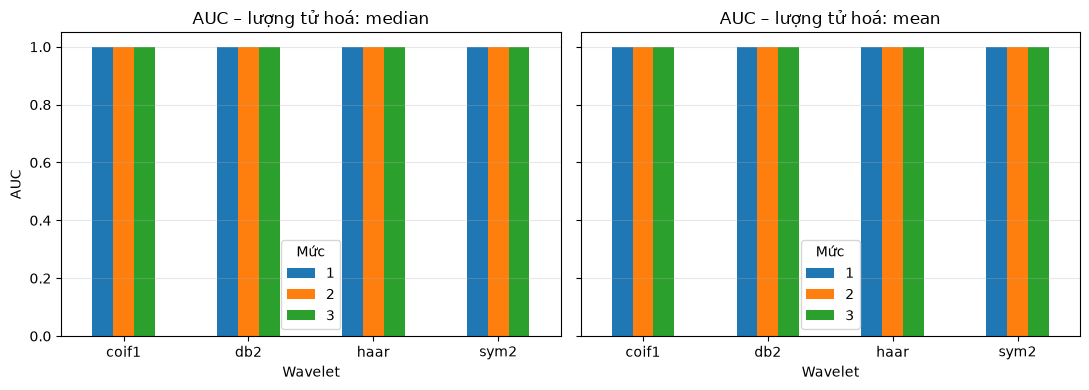

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, q in zip(axes, ("median", "mean")):
    pv = summary[summary.quant == q].pivot(index="wavelet", columns="level", values="auc")
    pv.plot(kind="bar", ax=ax, rot=0)
    ax.set_title(f"AUC – lượng tử hoá: {q}"); ax.set_xlabel("Wavelet"); ax.grid(alpha=.3, axis="y")
    ax.legend(title="Mức")
axes[0].set_ylabel("AUC"); plt.tight_layout(); plt.show()

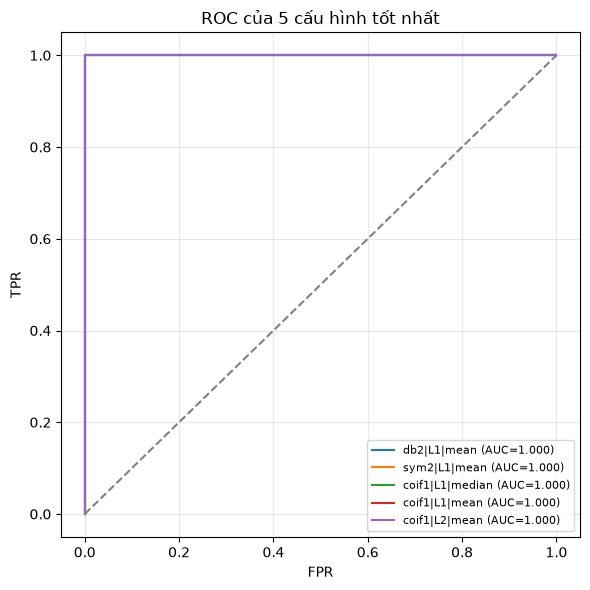

In [10]:
top = summary.head(5)
plt.figure(figsize=(6, 6))
for cfg in top.config:
    r = results[cfg]["roc"]
    plt.plot(r["fpr"], r["tpr"], drawstyle="steps-post", label=f"{cfg} (AUC={r['auc']:.3f})")
plt.plot([0, 1], [0, 1], "--", color="gray")
plt.xlabel("FPR"); plt.ylabel("TPR"); plt.title("ROC của 5 cấu hình tốt nhất")
plt.legend(loc="lower right", fontsize=8); plt.grid(alpha=.3); plt.tight_layout()
plt.savefig("output/roc_top5.png", dpi=150); plt.show()

## 6. Phân tích trường hợp phân loại sai
Dùng cấu hình mặc định tại ngưỡng đã chọn. Bảng bên dưới cho biết loại biến đổi nào khiến hash lệch nhiều nhất
(cặp tương tự bị bỏ sót) và loại cặp khác nhau nào bị nhầm là giống.

In [11]:
df["pred"] = (df.distance <= best_t).astype(int)
fn = df[(df.label == 1) & (df.pred == 0)]
fp = df[(df.label == 0) & (df.pred == 1)]
print(f"Bỏ sót (FN): {len(fn)} | Nhầm là giống (FP): {len(fp)}")

pos = (df[df.label == 1].groupby("variant")
       .agg(so_cap=("distance", "size"), kc_trung_binh=("distance", "mean"),
            kc_lon_nhat=("distance", "max"), ty_le_bo_sot=("pred", lambda s: 1 - s.mean()))
       .sort_values("kc_trung_binh", ascending=False))
print("\nCặp TƯƠNG TỰ theo loại biến đổi:")
display(pos.round(3))

neg = (df[df.label == 0].groupby("variant")
       .agg(so_cap=("distance", "size"), kc_trung_binh=("distance", "mean"),
            ty_le_nham=("pred", "mean")).sort_values("ty_le_nham", ascending=False))
print("Cặp KHÁC NHAU theo biến thể của ảnh thứ hai:")
display(neg.round(3))

errors = pd.concat([fn.assign(loai_loi="FN"), fp.assign(loai_loi="FP")])
errors.to_csv("output/error_cases.csv", index=False)

Bỏ sót (FN): 0 | Nhầm là giống (FP): 1

Cặp TƯƠNG TỰ theo loại biến đổi:


,so_cap,kc_trung_binh,kc_lon_nhat,ty_le_bo_sot
variant,,,,
crop_90pct,15,6.600,14,0.0
rotate_5deg,15,5.133,10,0.0
brighten,15,0.933,5,0.0
blur,15,0.067,1,0.0
darken,15,0.067,1,0.0
gauss_noise,15,0.067,1,0.0
jpeg_q30,15,0.067,1,0.0


Cặp KHÁC NHAU theo biến thể của ảnh thứ hai:


,so_cap,kc_trung_binh,ty_le_nham
variant,,,
none,18,30.222,0.056
blur,12,28.083,0.000
crop_90pct,12,33.833,0.000
brighten,13,31.000,0.000
darken,16,30.875,0.000
gauss_noise,12,32.000,0.000
jpeg_q30,9,31.333,0.000
rotate_5deg,13,28.462,0.000


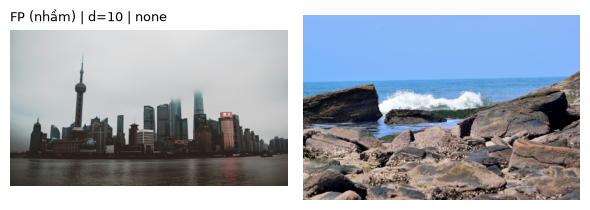

In [12]:
show = pd.concat([fn.sort_values("distance", ascending=False).head(3),
                  fp.sort_values("distance").head(3)])
if show.empty:
    print("Không có cặp sai ở ngưỡng này (thường gặp khi dùng dữ liệu giả lập dễ).")
else:
    fig, axes = plt.subplots(len(show), 2, figsize=(6, 3 * len(show)), squeeze=False)
    for ax_row, r in zip(axes, show.itertuples()):
        for ax, key in zip(ax_row, (r.img1, r.img2)):
            ax.imshow(cv2.cvtColor(images[key], cv2.COLOR_BGR2RGB)); ax.axis("off")
        kind = "FN (bỏ sót)" if r.label == 1 else "FP (nhầm)"
        ax_row[0].set_title(f"{kind} | d={r.distance} | {r.variant}", fontsize=9, loc="left")
    plt.tight_layout(); plt.show()

## 7. Nhận xét và hạn chế
*(Cập nhật số liệu theo kết quả chạy trên dữ liệu thật của nhóm.)*

**Kết quả chính**
- Bảng chỉ số theo ngưỡng cho thấy đánh đổi giữa Recall và Specificity: ngưỡng nhỏ → ít nhầm nhưng dễ bỏ sót; ngưỡng lớn → ngược lại.
- AUC được tính từ điểm số `-distance`; so sánh các cấu hình ở mục 5 để chọn wavelet, mức phân rã và cách lượng tử hoá phù hợp.

**Hạn chế**
1. **Chỉ dùng hệ số xấp xỉ LL:** hash chỉ mã hoá cấu trúc sáng–tối tổng quát, bỏ qua chi tiết (LH, HL, HH) nên khó phân biệt các ảnh có bố cục độ sáng giống nhau.
2. **Nhạy với biến đổi hình học:** xoay, cắt, lật, dịch chuyển làm lệch vị trí các hệ số → khoảng cách tăng mạnh dù cùng nội dung.
3. **Hash 64 bit:** không gian nhỏ, có thể trùng/gần trùng với ảnh khác nhau; ảnh gần như đơn sắc cho hash không ổn định (trung vị/trung bình nằm sát các hệ số).
4. **Ngưỡng chọn trên chính tập đánh giá:** Youden J tối ưu trên cùng dữ liệu nên kết quả hơi lạc quan; nên chọn ngưỡng trên tập huấn luyện và báo cáo trên tập kiểm tra riêng.
5. **Dữ liệu và cách tạo cặp:** cặp tương tự được tạo nhân tạo từ vài biến đổi; số ảnh gốc ít làm AUC dao động. Ảnh bị thu nhỏ (tối đa 512 px) trước khi biến đổi để chạy nhanh.
6. **Bảng so sánh:** khi AUC của nhiều cấu hình gần bằng nhau, chênh lệch nhỏ chưa chắc có ý nghĩa thống kê.